## 001. Initial EDA 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Loading cleaned/Interim dataset 
*from data/interim/DataCoSupplyChain_M5_cleaned.csv*

In [3]:
from pathlib import Path

data_path = Path("../data/interim/DataCoSupplyChain_M5_cleaned.csv")
df = pd.read_csv(data_path, encoding="latin-1")

In [4]:
print("Dataset shape:", df.shape)
print("\n Unique orders:", df["Order Id"].nunique())
df.head()

Dataset shape: (180519, 53)

 Unique orders: 65752


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-15 11:24:00,Standard Class


#### Missing-value analysis

In [5]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

missing = missing[missing["Missing Count"] > 0]
display(missing.sort_values("Missing Percentage", ascending=False))

,Missing Count,Missing Percentage
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Zipcode,3,0.00
Customer Lname,8,0.00


### Check order and delivery statuses

In [6]:
print("Order status counts:")
print(df["Order Status"].value_counts())
print("------------------------------------------------------")
print("\nDelivery status counts:")
print(df["Delivery Status"].value_counts())

Order status counts:
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64
------------------------------------------------------

Delivery status counts:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


### Delivery_Duration_Analysis
##### Analysis:           Result 
* Total records:      180519
* Missing actual durations: 0
* Average delivery duration: 3.50 days
* Median delivery duration: 3 days
* Maximum delivery duration: 6 days
* IQR outliers: 0
* Delivered later than scheduled: 103400
* Delivered on schedule: 33753
* Delivered earlier than scheduled: 43366
#
reference: **Delivery_Duration_Analysis_Summary.csv**
in
[`reports/Delivery_Duration_Analysis_Summary.csv`](./reports/Delivery_Duration_Analysis_Summary.csv)

### shipping status analysis

In [7]:
# Keep the original dataset unchanged
shipping_df = df.copy()

# Filter out cancelled shipments for this duration analysis
completed_shipping = shipping_df[
    shipping_df["Delivery Status"] != "Shipping canceled"
].copy()

print("Original rows:", len(shipping_df))
print("Rows included:", len(completed_shipping))
print(
    "Cancelled rows excluded:",
    len(shipping_df) - len(completed_shipping)
)

Original rows: 180519
Rows included: 172765
Cancelled rows excluded: 7754


reference: **Order_StatusAnalysis.ipynb** in
[`notebooks/Order_StatusAnalysis.ipynb`](./notebooks/Order_StatusAnalysis.ipynb)

### Shipping duration analysis

,Days for shipping (real),Days for shipment (scheduled)
count,172765.000000,172765.000000
mean,3.498596,2.933100
std,1.623446,1.373405
min,0.000000,0.000000
25%,2.000000,2.000000
50%,3.000000,4.000000
75%,5.000000,4.000000
max,6.000000,4.000000


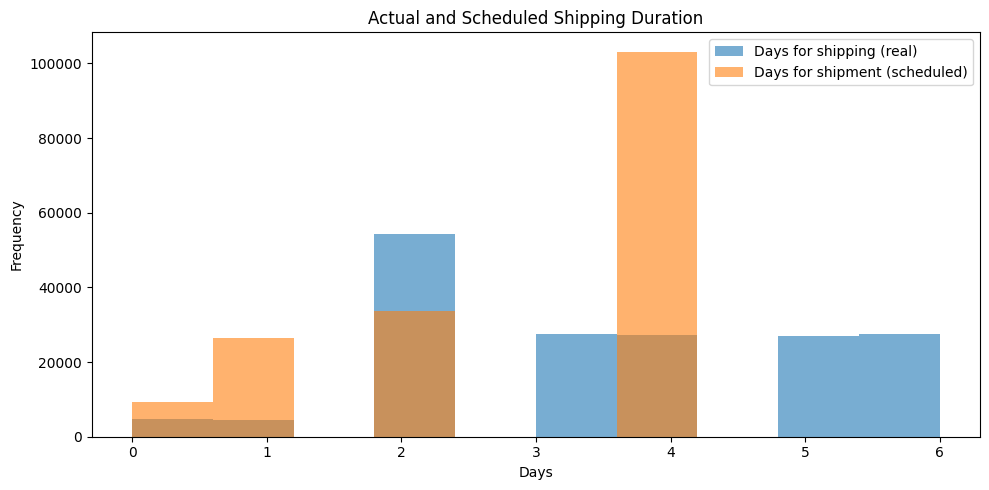

In [8]:
duration_cols = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]

display(completed_shipping[duration_cols].describe())

completed_shipping[duration_cols].plot(
    kind="hist", bins=10, alpha=0.6,
    figsize=(10, 5)
)

plt.title("Actual and Scheduled Shipping Duration")
plt.xlabel("Days")
plt.tight_layout()
plt.show()

**Insight:** This histogram uses 172,765 non-canceled order-item rows. Actual duration is most frequent at 2 days (54,205 rows), while the scheduled duration is most frequent at 4 days (103,153 rows). The mean actual duration is 3.50 days versus a scheduled mean of 2.93 days. These are separate distributions; compare paired durations to determine whether each shipment was early or late.

### Comparing shipping durations

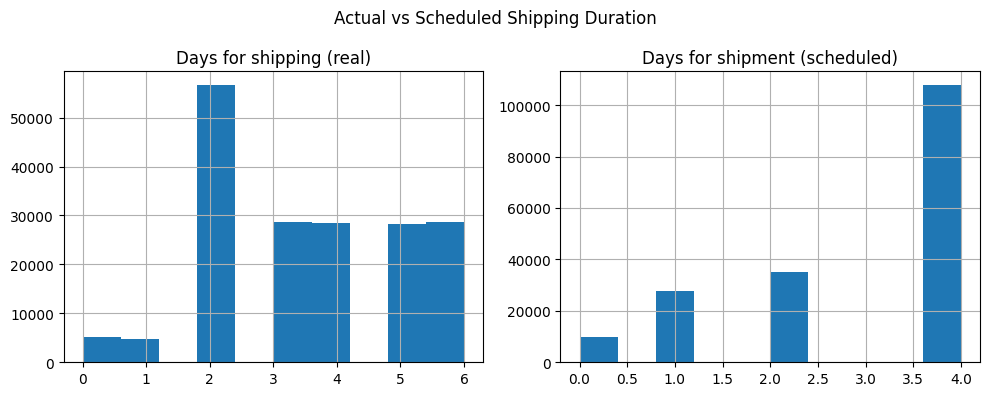

In [9]:
duration_cols = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)"
]

df[duration_cols].hist(figsize=(10, 4), bins=10)
plt.suptitle("Actual vs Scheduled Shipping Duration")
plt.tight_layout()
plt.show()

**Insight:** These two histograms include all 180,519 rows, including canceled shipments. Actual duration is most frequent at 2 days (56,618 rows), while scheduled duration is most frequent at 4 days (107,752 rows). Actual values span 0-6 days and scheduled values are concentrated at 0-4 days. Because the plots show separate distributions, they do not by themselves show which individual orders were late.

### Exploring order volume over time

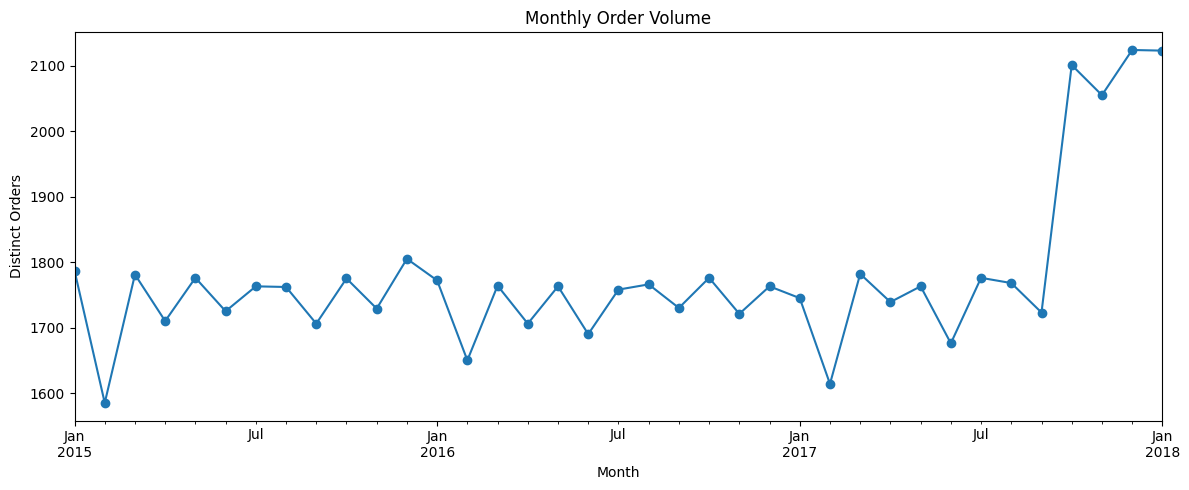

In [10]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"],
    errors="coerce"
)

monthly_orders = (
    df.dropna(subset=["order date (DateOrders)"])
      .set_index("order date (DateOrders)")
      .resample("MS")["Order Id"]
      .nunique()
)

monthly_orders.plot(figsize=(12, 5), marker="o")
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Distinct Orders")
plt.tight_layout()
plt.show()

**Insight:** Distinct-order volume stays within a fairly narrow monthly range for most of the 37-month series, from 1,585 orders in February 2015 to a peak of 2,124 in December 2017. Counts are higher in the final months, but January 2018 is the endpoint, so the chart alone cannot establish a sustained growth trend.

In [11]:
status = df['Order Status'].astype('string').str.strip().str.upper()
total_records = len(df)
status_summary = (status.value_counts(dropna=False)
                  .rename_axis('Order Status').reset_index(name='Count'))
status_summary['Percentage'] = (status_summary['Count'] / total_records * 100).round(2)
status_summary = status_summary.sort_values('Count', ascending=False).reset_index(drop=True)
status_summary

,Order Status,Count,Percentage
0,COMPLETE,59491,32.96
1,PENDING_PAYMENT,39832,22.07
2,PROCESSING,21902,12.13
3,PENDING,20227,11.2
4,CLOSED,19616,10.87
5,ON_HOLD,9804,5.43
6,SUSPECTED_FRAUD,4062,2.25
7,CANCELED,3692,2.05
8,PAYMENT_REVIEW,1893,1.05


### Delivery status percentages

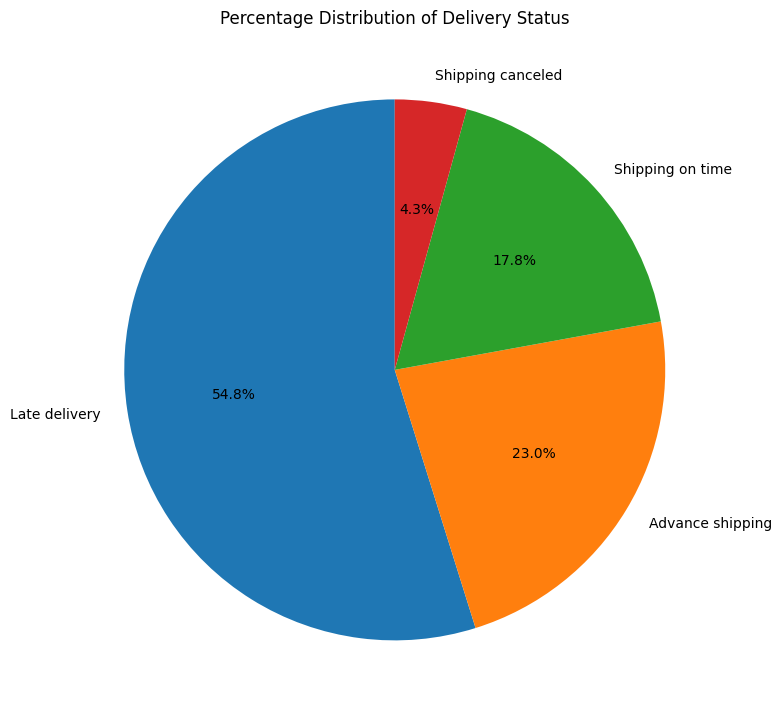

In [12]:
status_percent = (
    df["Delivery Status"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(8, 8))
plt.pie(
    status_percent.values,
    labels=status_percent.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage Distribution of Delivery Status")
plt.tight_layout()
plt.show()

**Insight:** Late delivery is the largest slice, representing 54.8% of order-item rows. Advance shipping represents 23.0%, shipping on time 17.8%, and shipping canceled 4.3%. The late share is more than twice the on-time share; cancellations are a separate outcome and should not be grouped with successful deliveries.

### identifying factors associated with late deliveries

In [13]:
keywords = [
    "delivery", "shipping", "date", "region",
    "country", "state", "mode", "category",
    "quantity", "status"
]

for col in df.columns:
    if any(word in col.lower() for word in keywords):
        print(col)

Days for shipping (real)
Delivery Status
Late_delivery_risk
Category Id
Category Name
Customer Country
Customer State
Order Country
order date (DateOrders)
Order Item Quantity
Order Region
Order State
Order Status
Product Category Id
Product Status
shipping date (DateOrders)
Shipping Mode


#### 01. Late-delivery rate by shipping mode

In [14]:
mode_analysis = (
    df.assign(
        is_late=df["Delivery Status"].eq("Late delivery")
    )
    .groupby("Shipping Mode")
    .agg(
        total_rows=("is_late", "size"),
        late_rows=("is_late", "sum")
    )
)

mode_analysis["Late Rate (%)"] = (
    mode_analysis["late_rows"]
    / mode_analysis["total_rows"] * 100
)

display(mode_analysis.sort_values("Late Rate (%)", ascending=False))

,total_rows,late_rows,Late Rate (%)
Shipping Mode,,,
First Class,27814,26513,95.322499
Second Class,35216,26987,76.632781
Same Day,9737,4454,45.743042
Standard Class,107752,41023,38.071683


                total_rows  late_rows  late_rate_pct
Shipping Mode                                       
First Class          27814      26513      95.322499
Second Class         35216      26987      76.632781
Same Day              9737       4454      45.743042
Standard Class      107752      41023      38.071683


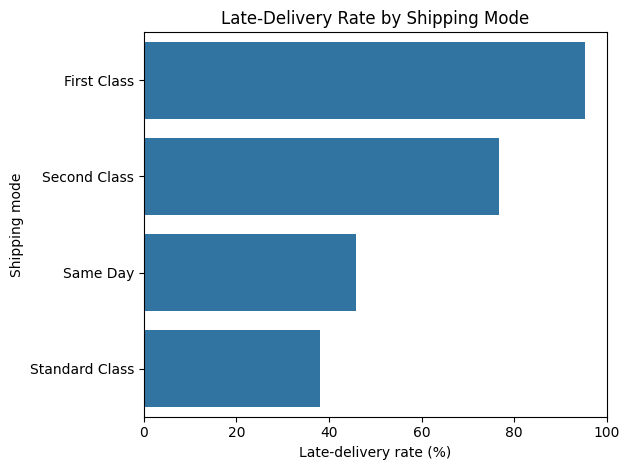

In [15]:

df["is_late"] = (
    df["Delivery Status"].eq("Late delivery")
)

mode_analysis = (
    df.groupby("Shipping Mode")
      .agg(
          total_rows=("is_late", "size"),
          late_rows=("is_late", "sum")
      )
)

mode_analysis["late_rate_pct"] = (
    mode_analysis["late_rows"]
    / mode_analysis["total_rows"] * 100
)

mode_analysis = mode_analysis.sort_values(
    "late_rate_pct", ascending=False
)

print(mode_analysis)

sns.barplot(
    data=mode_analysis.reset_index(),
    x="late_rate_pct",
    y="Shipping Mode"
)

plt.title("Late-Delivery Rate by Shipping Mode")
plt.xlabel("Late-delivery rate (%)")
plt.ylabel("Shipping mode")
plt.tight_layout()
plt.show()

**Insight:** The chart shows a large spread in row-level late rates: First Class is highest at 95.3% (26,513/27,814), followed by Second Class at 76.6% (26,987/35,216), Same Day at 45.7% (4,454/9,737), and Standard Class at 38.1% (41,023/107,752). Standard Class has the lowest rate but the largest number of late rows because it has the most observations. These are associations, not evidence that shipping mode causes delays.

### 02. Late-delivery rate by region

                total_rows  late_rows  late_rate_pct
Order Region                                        
Central Africa        1677        972      57.960644
South Asia            7731       4350      56.266977
East Africa           1852       1036      55.939525
Western Europe       27109      15140      55.848611
South of  USA         4045       2256      55.772559
Eastern Europe        3920       2182      55.663265
East of USA           6915       3849      55.661605
Southeast Asia        9539       5297      55.529930
Central Asia           553        306      55.334539
West Asia             6009       3322      55.283741


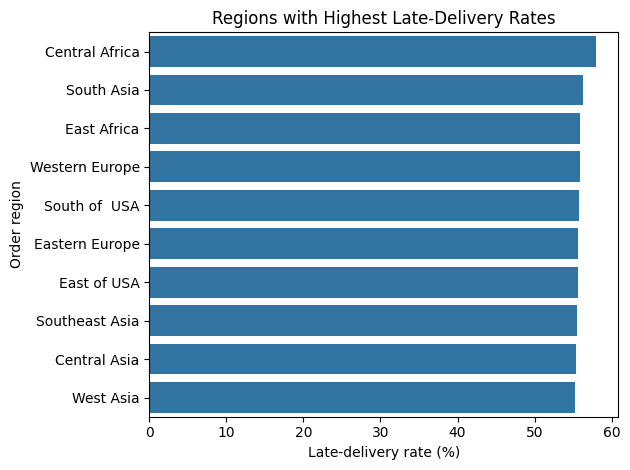

In [16]:
region_analysis = (
    df.groupby("Order Region")
      .agg(
          total_rows=("Delivery Status", "size"),
          late_rows=(
              "Delivery Status",
              lambda s: s.eq("Late delivery").sum()
          )
      )
)

region_analysis["late_rate_pct"] = (
    region_analysis["late_rows"]
    / region_analysis["total_rows"] * 100
)

region_analysis = region_analysis.sort_values(
    "late_rate_pct", ascending=False
)

print(region_analysis.head(10))

sns.barplot(
    data=region_analysis.head(10).reset_index(),
    x="late_rate_pct",
    y="Order Region"
)

plt.title("Regions with Highest Late-Delivery Rates")
plt.xlabel("Late-delivery rate (%)")
plt.ylabel("Order region")
plt.tight_layout()
plt.show()

**Insight:** Central Africa has the highest late-delivery rate among the ten regions plotted (58.0%; 972/1,677). The other displayed regions cluster fairly closely, around 55.3%-56.3%, so the gap between most regions is modest. Counts differ by region (for example, Central Asia has 553 rows versus Western Europe's 27,109); consider these sample sizes before interpreting the ranking.

## Additional EDA: order-level delivery outcomes

Rows represent order items, so compare row-level outcomes with distinct-order outcomes. The aggregation also checks whether key delivery attributes are consistent across items within an order.

In [18]:
order_level_eda = (
    df.groupby("Order Id", as_index=False)
      .agg(
          delivery_status=("Delivery Status", "first"),
          order_status=("Order Status", "first"),
          shipping_mode=("Shipping Mode", "first"),
          scheduled_days=("Days for shipment (scheduled)", "first"),
          actual_days=("Days for shipping (real)", "first"),
          order_date=("order date (DateOrders)", "first"),
          item_count=("Order Item Id", "size")
      )
)

row_status = df["Delivery Status"].value_counts().rename("count").to_frame()
row_status["rate_pct"] = df["Delivery Status"].value_counts(normalize=True).mul(100)
order_status_summary = order_level_eda["delivery_status"].value_counts().rename("count").to_frame()
order_status_summary["rate_pct"] = (
    order_level_eda["delivery_status"].value_counts(normalize=True).mul(100)
)
print("\n Item-row delivery outcomes")
display(row_status.round(2))
print("\n Distinct-order delivery outcomes")
display(order_status_summary.round(2))

order_fields = [
    "Delivery Status", "Order Status", "Shipping Mode",
    "Days for shipment (scheduled)", "Days for shipping (real)"
]
inconsistent_order_counts = df.groupby("Order Id")[order_fields].nunique().gt(1).sum()
print("\n Orders with inconsistent values across item rows:")
display(inconsistent_order_counts.rename("inconsistent_orders").to_frame())

print("\n Distinct-order Order Status by Delivery Status")
display(pd.crosstab(order_level_eda["order_status"], order_level_eda["delivery_status"]))


 Item-row delivery outcomes


,count,rate_pct
Delivery Status,,
Late delivery,98977,54.83
Advance shipping,41592,23.04
Shipping on time,32196,17.84
Shipping canceled,7754,4.30



 Distinct-order delivery outcomes


,count,rate_pct
delivery_status,,
Late delivery,36048,54.82
Advance shipping,15127,23.01
Shipping on time,11722,17.83
Shipping canceled,2855,4.34



 Orders with inconsistent values across item rows:


,inconsistent_orders
Delivery Status,0
Order Status,0
Shipping Mode,0
Days for shipment (scheduled),0
Days for shipping (real),0



 Distinct-order Order Status by Delivery Status


delivery_status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
order_status,,,,
CANCELED,0,0,1367,0
CLOSED,1777,4112,0,1360
COMPLETE,5174,12521,0,4021
ON_HOLD,858,2045,0,721
PAYMENT_REVIEW,159,405,0,140
PENDING,1797,4215,0,1309
PENDING_PAYMENT,3421,8256,0,2705
PROCESSING,1941,4494,0,1466
SUSPECTED_FRAUD,0,0,1488,0


## Additional EDA: delivery-date validation and shipping-mode overlap

Compare the calendar-day gap between the recorded order and shipping timestamps with the recorded actual shipping duration. Then inspect whether shipping modes share scheduled-duration values; without overlap, their raw late rates are not like-for-like comparisons.

In [19]:
order_dates = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
shipping_dates = pd.to_datetime(df["shipping date (DateOrders)"], errors="coerce")
calendar_days_elapsed = (shipping_dates - order_dates).dt.days
duration_mismatch = calendar_days_elapsed.ne(df["Days for shipping (real)"])

print(
    "\n Rows where calendar-day date gap differs from recorded actual duration:",
    int(duration_mismatch.sum()),
    f"({duration_mismatch.mean():.2%})"
)

display(
    df.assign(duration_mismatch=duration_mismatch)
      .groupby("Delivery Status")["duration_mismatch"]
      .agg(mismatch_rows="sum", row_count="size", mismatch_rate="mean")
      .assign(mismatch_rate_pct=lambda x: x["mismatch_rate"].mul(100))
      .drop(columns="mismatch_rate")
      .round(2)
)

mode_schedule_overlap = (
    df.groupby("Shipping Mode")["Days for shipment (scheduled)"]
      .agg(scheduled_day_values="nunique", min_days="min", max_days="max")
)
print("\n Scheduled-duration values represented within each shipping mode")
display(mode_schedule_overlap)

non_canceled = df[ df["Delivery Status"] != "Shipping canceled" ]
mode_schedule_rates = (
    non_canceled.assign(is_late=non_canceled["Delivery Status"].eq("Late delivery"))
      .groupby(["Shipping Mode", "Days for shipment (scheduled)"])
      .agg(order_items=("is_late", "size"), late_items=("is_late", "sum"), late_rate=("is_late", "mean"))
)
mode_schedule_rates["late_rate_pct"] = mode_schedule_rates["late_rate"].mul(100)
display(mode_schedule_rates.drop(columns="late_rate").round(2))


 Rows where calendar-day date gap differs from recorded actual duration: 4657 (2.58%)


,mismatch_rows,row_count,mismatch_rate_pct
Delivery Status,,,
Advance shipping,0,41592,0.00
Late delivery,4454,98977,4.50
Shipping canceled,203,7754,2.62
Shipping on time,0,32196,0.00



 Scheduled-duration values represented within each shipping mode


,scheduled_day_values,min_days,max_days
Shipping Mode,,,
First Class,1,1,1
Same Day,1,0,0
Second Class,1,2,2
Standard Class,1,4,4


,,order_items,late_items,late_rate_pct
Shipping Mode,Days for shipment (scheduled),,,
First Class,1,26513,26513,100.00
Same Day,0,9293,4454,47.93
Second Class,2,33806,26987,79.83
Standard Class,4,103153,41023,39.77


## Additional EDA: monthly late and cancellation rates

    Use one row per order for rates, and inspect item coverage alongside order counts. The series ends in January 2018.

,distinct_orders,item_rows,mean_items_per_order,late_rate_pct,cancellation_rate_pct
month,,,,,
2015-01-01,1787,5322,2.98,53.89,4.14
2015-02-01,1585,4729,2.98,54.95,5.05
2015-03-01,1781,5362,3.01,54.91,4.44
2015-04-01,1710,5126,3.00,54.21,4.15
2015-05-01,1776,5357,3.02,54.56,5.18
2015-06-01,1725,5134,2.98,54.55,4.29
2015-07-01,1763,5299,3.01,54.62,3.35
2015-08-01,1762,5273,2.99,54.82,4.77
2015-09-01,1706,5140,3.01,55.74,4.22


Monthly late-rate range: 52.45% to 57.28%


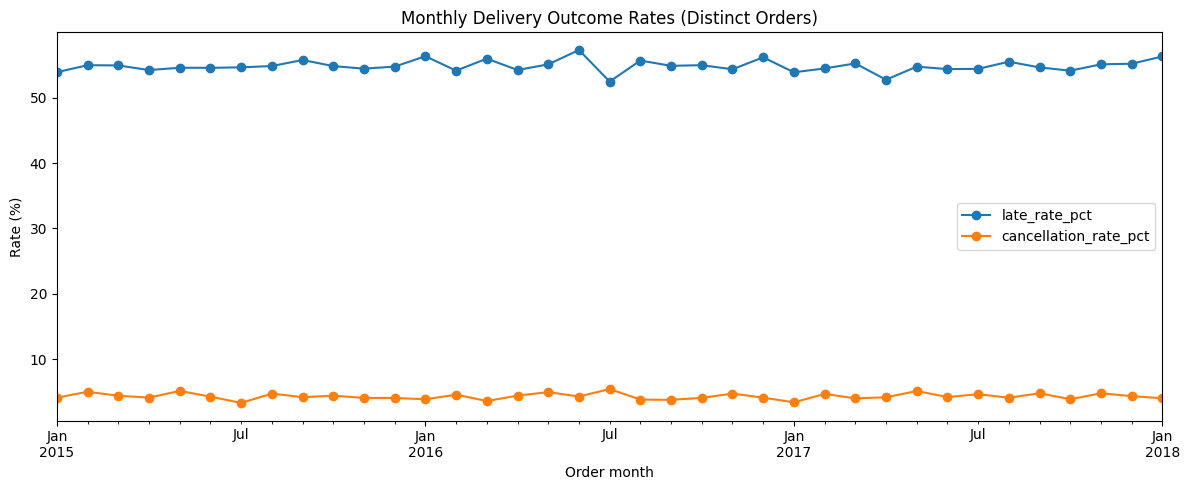

In [20]:
order_level_eda["order_date"] = pd.to_datetime(order_level_eda["order_date"], errors="coerce")
monthly_outcomes = (
    order_level_eda.dropna(subset=["order_date"])
      .assign(month=lambda x: x["order_date"].dt.to_period("M").dt.to_timestamp())
      .groupby("month")
      .agg(
          distinct_orders=("Order Id", "nunique"),
          item_rows=("item_count", "sum"),
          mean_items_per_order=("item_count", "mean"),
          late_rate=("delivery_status", lambda x: x.eq("Late delivery").mean()),
          cancellation_rate=("delivery_status", lambda x: x.eq("Shipping canceled").mean())
      )
)
monthly_outcomes[["late_rate_pct", "cancellation_rate_pct"]] = (
    monthly_outcomes[["late_rate", "cancellation_rate"]].mul(100)
)
display(monthly_outcomes[["distinct_orders", "item_rows", "mean_items_per_order", "late_rate_pct", "cancellation_rate_pct"]].round(2))
print(
    "Monthly late-rate range:",
    f"{monthly_outcomes['late_rate_pct'].min():.2f}% to "
    f"{monthly_outcomes['late_rate_pct'].max():.2f}%"
)

ax = monthly_outcomes[["late_rate_pct", "cancellation_rate_pct"]].plot(
    figsize=(12, 5), marker="o"
)
ax.set_title("Monthly Delivery Outcome Rates (Distinct Orders)")
ax.set_xlabel("Order month")
ax.set_ylabel("Rate (%)")
plt.tight_layout()
plt.show()

## Additional EDA: financial metric checks

Inspect the row-level distribution of the benefit field by market, including its median and negative-value share. These are dataset metric patterns, not verified accounting profit; confirm field definitions and currency before interpreting totals.

In [ ]:
print(
    "Benefit per order equals Order Profit Per Order on every row:",
    bool(df["Benefit per order"].equals(df["Order Profit Per Order"]))
)

market_financial = (
    df.groupby("Market")
      .agg(
          item_rows=("Order Item Id", "size"),
          median_benefit=("Benefit per order", "median"),
          negative_benefit_rows=("Benefit per order", lambda x: x.lt(0).sum()),
          negative_benefit_share=("Benefit per order", lambda x: x.lt(0).mean()),
          benefit_p99=("Benefit per order", lambda x: x.quantile(0.99)),
          benefit_min=("Benefit per order", "min")
      )
)
market_financial["negative_benefit_pct"] = market_financial["negative_benefit_share"].mul(100)
display(
    market_financial.drop(columns="negative_benefit_share")
      .sort_values("median_benefit", ascending=False)
      .round(2)
)

Benefit per order equals Order Profit Per Order on every row: True


,item_rows,median_benefit,negative_benefit_rows,benefit_p99,benefit_min,negative_benefit_pct
Market,,,,,,
Europe,50252,32.78,9420,191.67,-4274.98,18.75
LATAM,51594,32.02,9588,179.99,-1286.87,18.58
Africa,11614,31.49,2158,181.92,-1069.15,18.58
USCA,25799,31.49,4812,179.98,-1336.37,18.65
Pacific Asia,41260,29.18,7806,185.21,-3366.00,18.92


# Initial EDA Findings

## Key observations
1. **Dataset scope:** The cleaned dataset contains 180,519 order-item rows, 53 columns, and 65,752 distinct orders (about 2.75 rows per order). It covers January 2015 through January 2018.
2. **Order volume:** Monthly distinct-order counts range from 1,585 (February 2015) to 2,124 (December 2017). Volume is broadly steady, with somewhat higher counts at the end of the observed period; January 2018 is the endpoint, so this does not establish continuing growth.
3. **Delivery status:** `Late delivery` is the most common status (98,977 rows; 54.8%). `Advance shipping` accounts for 23.0%, `Shipping on time` 17.8%, and `Shipping canceled` 4.3%.
4. **Shipping duration:** Excluding the 7,754 rows labeled `Shipping canceled`, actual shipping duration averages 3.50 days versus 2.93 scheduled days. Actual duration is greater than scheduled on 98,977 rows, equal on 32,196, and less on 41,592. These counts align exactly with the `Late delivery`, `Shipping on time`, and `Advance shipping` labels, respectively, among non-canceled rows.
5. **Shipping-mode differences:** Row-level late-delivery rates are First Class 95.3% (26,513/27,814), Second Class 76.6% (26,987/35,216), Same Day 45.7% (4,454/9,737), and Standard Class 38.1% (41,023/107,752). Standard Class has the lowest rate but the highest late-row count because it has the largest group. The raw rates may also reflect different scheduled windows and route mixes, so they are not a like-for-like causal comparison.
6. **Regional differences:** Central Africa has the highest observed regional late rate (58.0%; 972/1,677), while Canada has the lowest (48.8%; 468/959). Most of the plotted high-rate regions are clustered around 55%-56%.
7. **Financial pattern:** `Benefit per order` averages 21.97 and has a median of 31.52; 33,784 rows (18.7%) are negative. The mean/median gap and extreme losses warrant checking the metric definition and outliers.
8. **Risk-flag consistency:** `Late_delivery_risk` matches the `Delivery Status == 'Late delivery'` indicator on all 180,519 rows. This is a consistency check, not an independent signal for predicting delivery outcome.

## Data limitations
- **Order-item grain:** Rows are order items, not unique orders. Row-level rates may differ from order-level rates, and observations within the same order are not independent.
- **Missing fields:** `Product Description` is missing on all 180,519 rows; `Order Zipcode` is missing on 155,679 rows (86.2%). Customer surname and zipcode have 8 and 3 missing values, respectively. This constrains product-detail and location analysis.
- **Status and duration interpretation:** The duration/status alignment above holds after excluding rows labeled `Shipping canceled`; confirm these definitions and continue to treat cancellations separately. Non-canceled status does not necessarily prove every order is completed, given the separate order-status field.
- **Target leakage:** Since `Late_delivery_risk` exactly reproduces the late-delivery label, it must not be used as a predictor of that outcome. Use only information available before delivery for any prospective model.
- **Uneven groups, confounding, and limited history:** Region and shipping-mode group sizes vary. Shipping-mode rates may reflect different promised delivery windows, routes, or customer/order mixes, not just mode performance. Smaller-group rates are less stable, and the dataset spans only Jan 2015-Jan 2018.
- **Financial interpretation:** Currency and calculation definitions for `Benefit per order` are not established here; negative and extreme values can affect summary statistics.
- **Privacy:** Source data contains customer-identifying and credential-like fields. Do not expose them in reports or visualizations.
- These are descriptive observations and do not establish causes or guarantee generalizability.
